# 칭찬처럼 보이는데 사실은 비꼬는 말일까?
## BERT를 활용한 영어 SNS 문장의 아이러니 탐지

“Great, another meeting that could have been an email.”에서 `Great`만 보면
긍정적으로 보이지만, 전체 문장은 불필요한 회의에 대한 비꼼으로 읽을 수 있다.
이 프로젝트는 문장의 표면적인 단어와 문맥 사이의 불일치를 BERT가 학습할 수 있는지 살펴본다.

**연구 질문:** 양방향 문맥을 학습한 BERT는 단어 빈도를 이용하는 기준 모델보다
아이러니를 잘 탐지하는가? 실제 성능 비교 후에 답한다.

감정 분석과 달리 **아이러니 여부**를 예측한다. 아이러니는 비꼼보다 넓은 개념이며,
이진 분류 결과가 작성자의 진짜 의도나 감정을 확정하지는 않는다.
SNS 모니터링에서 단순 긍정 단어 검색을 보완하는 연구용 보조 신호로 활용할 수 있다.

### 실행 안내
Google Colab에 이 파일을 업로드 → 런타임 → 런타임 유형 변경 → GPU → 위에서부터 실행.
데이터와 모델을 다운로드하므로 인터넷이 필요하다. 아래 학습은 전체 데이터·3 epoch가 기본이다.
GPU 메모리가 부족하면 배치 크기를 8에서 4로 낮춘다. CPU도 가능하지만 오래 걸릴 수 있다.
**학습 전 저장된 성능 수치는 없다.** 실행하면 `outputs/`에 실제 결과가 저장된다.


In [ ]:
%pip install -q transformers==4.57.1 datasets==4.4.1 accelerate==1.11.0 scikit-learn pandas matplotlib


In [1]:
import json
import platform
import random
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
import datasets
from IPython.display import display
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, Trainer, TrainingArguments, set_seed)

SEED = 42
MODEL_ID = "google-bert/bert-base-uncased"
DATASET_ID = "cardiffnlp/tweet_eval"
MAX_LENGTH = 128
EPOCHS = 3
BATCH_SIZE = 8
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
set_seed(SEED)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("torch:", torch.__version__, "transformers:", transformers.__version__)


GPU: NVIDIA GeForce RTX 5050 Laptop GPU
torch: 2.11.0+cu128 transformers: 4.57.1


## 1. 사용한 모델과 데이터셋 소개

### 모델: google-bert/bert-base-uncased
영어 BERT Base는 Transformer Encoder 12층으로 구성되며 앞뒤 문맥을 함께 반영한다.
이 체크포인트는 영어 대소문자를 구분하지 않는다. MLM과 NSP로 사전학습된
언어 표현을 가져오고, 이번 작업을 위한 2개 출력의 분류층을 붙인다.
분류층은 새로 초기화되므로 **학습 전 예측은 의미 있는 아이러니 판정이 아니다.**
이번에는 Encoder와 분류층을 모두 업데이트하는 전체 Fine-tuning을 수행한다.

### 데이터: TweetEval의 irony 구성
SemEval-2018의 영어 트윗 아이러니 탐지 자료를 TweetEval 형태로 제공한다.
공식 분할은 학습 2,862개, 검증 955개, 테스트 784개이며
`0 = non_irony`, `1 = irony`이다. 아래에서 실제 로딩 결과도 확인한다.
학습 자료는 가중치 학습에, 검증 자료는 최적 epoch 선택에,
테스트 자료는 선택이 끝난 모델의 최종 성능 보고에만 사용한다.

출처: [BERT 모델 카드](https://huggingface.co/google-bert/bert-base-uncased),
[TweetEval 데이터 카드](https://huggingface.co/datasets/cardiffnlp/tweet_eval),
[TweetEval 공식 저장소](https://github.com/cardiffnlp/tweeteval),
[BERT 논문](https://arxiv.org/abs/1810.04805).
데이터 카드의 라이선스 표기는 unknown이므로 재배포나 상용 활용 전 원출처 조건을 확인한다.


In [2]:
raw = load_dataset(DATASET_ID, "irony")
label_names = raw["train"].features["label"].names
assert label_names == ["non_irony", "irony"], label_names
id2label = dict(enumerate(label_names))
label2id = {name: i for i, name in id2label.items()}
print(raw)
counts = pd.DataFrame({split: np.bincount(raw[split]["label"], minlength=2)
                       for split in raw}, index=label_names).T
display(counts)
display(raw["train"].to_pandas().head())
counts.to_csv(OUT / "label_counts.csv")


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 2862
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 784
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 955
    })
})
            non_irony  irony
train            1417   1445
test              473    311
validation        499    456
                                                text  label
0  seeing ppl walking w/ crutches makes me really...      1
1  look for the girl with the broken smile, ask h...      0
2  Now I remember why I buy books online @user #s...      1
3  @user @user So is he banded from wearing the c...      1
4  Just found out there are Etch A Sketch apps.  ...      1


## 2. Tokenizer를 이용한 데이터 전처리

WordPiece 토크나이저가 문장을 서브워드로 나누고 `[CLS]`, `[SEP]`를 추가한다.
`input_ids`는 토큰 번호, `attention_mask`는 실제 토큰과 패딩을 구분하는 마스크,
`token_type_ids`는 문장 구분 번호이며 이번 단일 문장 입력에서는 보통 모두 0이다.
`[CLS]` 위치에서 얻은 표현을 이용해 분류한다.

이모지, 부정어, 느낌표, 해시태그는 아이러니 단서일 수 있어 추가로 삭제하지 않는다.
대소문자 정규화는 uncased 토크나이저가 수행한다. 입력 길이는 특수 토큰을 포함해
128토큰으로 제한하고, 배치 내부의 최장 길이에 맞춰 동적 패딩한다.
512토큰은 기본 BERT의 최대 한도이며, 여기서는 비용을 줄이려고 128을 선택했다.
길이 제한으로 잃는 정보가 있는지 **학습 데이터에서** 잘림 비율을 확인한다.


문장: Great, another meeting that could have been an email.
토큰: ['[CLS]', 'great', ',', 'another', 'meeting', 'that', 'could', 'have', 'been', 'an', 'email', '.', '[SEP]']
인코딩: {'input_ids': [101, 2307, 1010, 2178, 3116, 2008, 2071, 2031, 2042, 2019, 10373, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}
학습 데이터 길이 중앙값: 22.0
128토큰 초과 비율: 0.00034940600978336826
{'labels': (2,), 'input_ids': (2, 27), 'token_type_ids': (2, 27), 'attention_mask': (2, 27)}


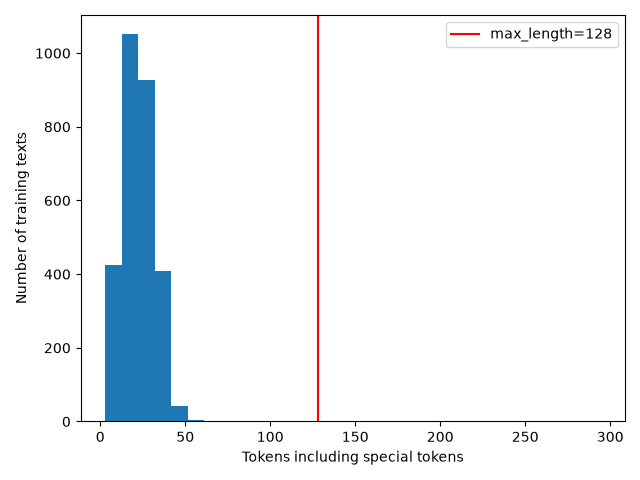

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
example = "Great, another meeting that could have been an email."
encoded_example = tokenizer(example, truncation=True, max_length=MAX_LENGTH)
print("문장:", example)
print("토큰:", tokenizer.convert_ids_to_tokens(encoded_example["input_ids"]))
print("인코딩:", encoded_example)

lengths = [len(ids) for ids in tokenizer(list(raw["train"]["text"]), truncation=False)["input_ids"]]
print("학습 데이터 길이 중앙값:", np.median(lengths))
print("128토큰 초과 비율:", np.mean(np.array(lengths) > MAX_LENGTH))
plt.hist(lengths, bins=30)
plt.axvline(MAX_LENGTH, color="red", label="max_length=128")
plt.xlabel("Tokens including special tokens")
plt.ylabel("Number of training texts")
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "token_lengths.png")
plt.show()

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized = raw.map(tokenize, batched=True, remove_columns=["text"])
tokenized = tokenized.rename_column("label", "labels")
collator = DataCollatorWithPadding(tokenizer=tokenizer)
demo_batch = collator([tokenized["train"][i] for i in range(2)])
print({key: tuple(value.shape) for key, value in demo_batch.items()})


## 3. 사전학습 모델 Fine-tuning

먼저 TF-IDF + 로지스틱 회귀 기준 모델을 학습한다. TF-IDF는 단어와
인접한 두 단어의 빈도를 이용하지만 BERT처럼 깊은 문맥 표현을 만들지는 않는다.
학습 데이터로만 어휘와 분류기를 학습하며, 기준 모델의 하이퍼파라미터는 고정한다.
그 다음 BERT에 같은 분할을 적용한다.

| 설정 | 값 |
|---|---|
| Epoch | 3 |
| 학습률 | 2e-5 |
| 학습 배치 | 8 |
| 최대 입력 | 128토큰 |
| Weight decay | 0.01 |
| Warmup 비율 | 0.1 |
| 최적 모델 선택 | 검증 macro F1 |
| Seed | 42 |

`Trainer`는 정답 라벨과 모델 출력으로 Cross-Entropy loss를 계산하고
역전파로 모든 층의 가중치를 업데이트한다. 매 epoch 검증·체크포인트 저장을 수행한다.
테스트 성능을 보고 epoch를 선택하지 않는다.


In [4]:
def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=[0, 1], average="macro", zero_division=0)),
        "irony_f1": float(f1_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "irony_precision": float(precision_score(y_true, y_pred, pos_label=1, zero_division=0)),
        "irony_recall": float(recall_score(y_true, y_pred, pos_label=1, zero_division=0)),
    }

baseline = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000),
    LogisticRegression(max_iter=1000, random_state=SEED),
)
baseline.fit(raw["train"]["text"], raw["train"]["label"])
print("기준 모델 검증 성능:", calculate_metrics(
    raw["validation"]["label"], baseline.predict(raw["validation"]["text"])))

def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    return calculate_metrics(labels, np.argmax(logits, axis=-1))

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_ID, num_labels=2, id2label=id2label, label2id=label2id)
args = TrainingArguments(
    output_dir=str(OUT / "checkpoints"),
    learning_rate=2e-5,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=16,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    warmup_ratio=0.1,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    seed=SEED,
    data_seed=SEED,
    report_to="none",
    fp16=False,
)
trainer = Trainer(
    model=model, args=args,
    train_dataset=tokenized["train"], eval_dataset=tokenized["validation"],
    processing_class=tokenizer, data_collator=collator, compute_metrics=compute_metrics)
started = time.perf_counter()
train_result = trainer.train()
elapsed = time.perf_counter() - started
print(f"학습 시간: {elapsed / 60:.1f}분")
print("선택한 체크포인트:", trainer.state.best_model_checkpoint)
trainer.save_model(str(OUT / "best_model"))
tokenizer.save_pretrained(str(OUT / "best_model"))
trainer.save_state()


기준 모델 검증 성능: {'accuracy': 0.631413612565445, 'macro_f1': 0.6312353003124233, 'irony_f1': 0.6231263383297645, 'irony_precision': 0.608786610878661, 'irony_recall': 0.6381578947368421}
{'loss': 0.6933, 'grad_norm': 7.879115581512451, 'learning_rate': 9.074074074074075e-06, 'epoch': 0.14}
{'loss': 0.6666, 'grad_norm': 10.017870903015137, 'learning_rate': 1.8333333333333333e-05, 'epoch': 0.28}
{'loss': 0.6546, 'grad_norm': 5.006365776062012, 'learning_rate': 1.915113871635611e-05, 'epoch': 0.42}
{'loss': 0.6534, 'grad_norm': 11.656611442565918, 'learning_rate': 1.811594202898551e-05, 'epoch': 0.56}
{'loss': 0.6314, 'grad_norm': 15.724556922912598, 'learning_rate': 1.7080745341614907e-05, 'epoch': 0.7}
{'loss': 0.6255, 'grad_norm': 5.853899955749512, 'learning_rate': 1.6045548654244307e-05, 'epoch': 0.84}
{'loss': 0.642, 'grad_norm': 9.130630493164062, 'learning_rate': 1.5010351966873707e-05, 'epoch': 0.98}
{'eval_loss': 0.6108033061027527, 'eval_accuracy': 0.6701570680628273, 'eval_macro_f

## 4. 학습 과정 및 성능 평가

학습 loss가 줄어도 검증 loss가 증가하거나 검증 F1이 낮아지면 과적합 가능성이 있다.
Accuracy는 전체 정답 비율, macro F1은 두 클래스의 F1을 동일 비중으로 평균한 값이다.
아이러니 precision은 아이러니 예측 중 정답 비율, recall은 실제 아이러니 중 찾아낸 비율이다.
TweetEval 아이러니 비교를 위해 양성 클래스의 F1도 따로 보고한다.

최종 선택된 모델에 테스트 세트를 적용하고 TF-IDF 기준 모델과 비교한다.
혼동행렬의 행은 실제 라벨, 열은 예측 라벨이다. 아래 수치는 실행 결과로만 생성된다.


      loss  grad_norm  ...    total_flos  train_loss
0   0.6933   7.879116  ...           NaN         NaN
1   0.6666  10.017871  ...           NaN         NaN
2   0.6546   5.006366  ...           NaN         NaN
3   0.6534  11.656611  ...           NaN         NaN
4   0.6314  15.724557  ...           NaN         NaN
5   0.6255   5.853900  ...           NaN         NaN
6   0.6420   9.130630  ...           NaN         NaN
7      NaN        NaN  ...           NaN         NaN
8   0.5141  10.417624  ...           NaN         NaN
9   0.5138   9.316258  ...           NaN         NaN
10  0.5155  13.961617  ...           NaN         NaN
11  0.4855  20.292486  ...           NaN         NaN
12  0.5043  11.623116  ...           NaN         NaN
13  0.4620   6.584062  ...           NaN         NaN
14  0.4814  14.582998  ...           NaN         NaN
15     NaN        NaN  ...           NaN         NaN
16  0.3785  11.648743  ...           NaN         NaN
17  0.3269   4.650242  ...           NaN      

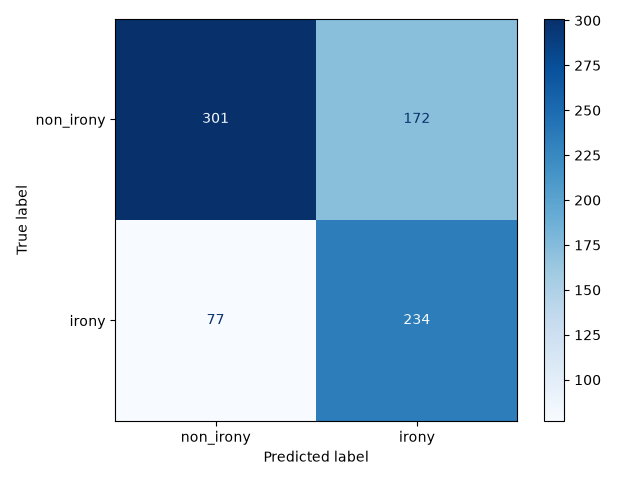

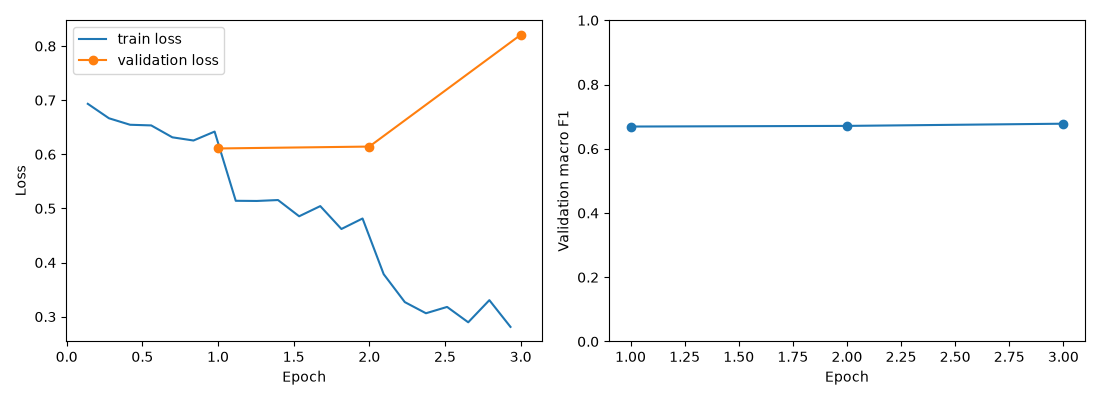

In [5]:
history = pd.DataFrame(trainer.state.log_history)
history.to_csv(OUT / "training_history.csv", index=False)
display(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train_logs = history.dropna(subset=["loss"])
eval_logs = history.dropna(subset=["eval_loss"])
axes[0].plot(train_logs["epoch"], train_logs["loss"], label="train loss")
axes[0].plot(eval_logs["epoch"], eval_logs["eval_loss"], marker="o", label="validation loss")
axes[0].set(xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].plot(eval_logs["epoch"], eval_logs["eval_macro_f1"], marker="o")
axes[1].set(xlabel="Epoch", ylabel="Validation macro F1", ylim=(0, 1))
plt.tight_layout()
plt.savefig(OUT / "learning_curves.png")
plt.show()

test_output = trainer.predict(tokenized["test"])
test_labels = np.array(raw["test"]["label"])
bert_predictions = np.argmax(test_output.predictions, axis=1)
baseline_predictions = baseline.predict(raw["test"]["text"])
results = {
    "TF-IDF + LogisticRegression": calculate_metrics(test_labels, baseline_predictions),
    "BERT fine-tuned": calculate_metrics(test_labels, bert_predictions),
}
comparison = pd.DataFrame(results).T
comparison.to_csv(OUT / "test_metrics.csv")
display(comparison)
print(classification_report(test_labels, bert_predictions, labels=[0, 1],
                            target_names=label_names, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(test_labels, bert_predictions, labels=[0, 1]),
                       display_labels=label_names).plot(cmap="Blues")
plt.tight_layout()
plt.savefig(OUT / "confusion_matrix.png")
plt.show()

test_probs = torch.softmax(torch.tensor(test_output.predictions), dim=-1).numpy()
predictions_table = pd.DataFrame({
    "text": raw["test"]["text"], "true_label": test_labels,
    "predicted_label": bert_predictions, "irony_probability": test_probs[:, 1],
    "confidence": test_probs.max(axis=1),
})
predictions_table.to_csv(OUT / "test_predictions.csv", index=False)
errors = predictions_table[predictions_table.true_label != predictions_table.predicted_label]
errors = errors.sort_values("confidence", ascending=False)
errors.to_csv(OUT / "misclassified.csv", index=False)
display(errors.head(10))

experiment = {
    "model": MODEL_ID, "dataset": DATASET_ID, "config": "irony",
    "seed": SEED, "epochs": EPOCHS, "max_length": MAX_LENGTH,
    "batch_size": BATCH_SIZE, "learning_rate": 2e-5,
    "split_sizes": {key: len(value) for key, value in raw.items()},
    "dataset_fingerprints": {key: value._fingerprint for key, value in raw.items()},
    "model_commit": getattr(model.config, "_commit_hash", None),
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "best_validation_macro_f1": trainer.state.best_metric,
    "training_seconds": elapsed, "test_results": results,
    "python": platform.python_version(), "torch": torch.__version__,
    "transformers": transformers.__version__, "datasets": datasets.__version__,
    "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
}
(OUT / "experiment.json").write_text(json.dumps(experiment, ensure_ascii=False, indent=2), encoding="utf-8")
delta = results["BERT fine-tuned"]["macro_f1"] - results["TF-IDF + LogisticRegression"]["macro_f1"]
print(f"BERT - 기준 모델 테스트 macro F1 차이: {delta:+.4f}")
print("단일 seed 결과이므로 성능 차이가 통계적으로 유의하다고 단정하지 않는다.")


## 5. 새로운 문장을 직접 입력하여 예측

저장된 최적 모델을 다시 불러와 추론한다. 아래 문장은 직접 만든 설명용 문장이며,
정답이 검증된 평가 데이터가 아니다. 학습 결과에 따라 예측이 달라질 수 있다.
두 클래스의 softmax 값을 출력하지만, 이것은 보정된 정확도나 의도의 확률이 아니다.
한국어 모델이 아니므로 **영어로 입력한다.**


In [6]:
inference_tokenizer = AutoTokenizer.from_pretrained(OUT / "best_model")
inference_model = AutoModelForSequenceClassification.from_pretrained(OUT / "best_model")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
inference_model.to(device).eval()

def predict_text(text):
    if not isinstance(text, str) or not text.strip():
        raise ValueError("비어 있지 않은 영어 문장을 입력하세요.")
    text = text.strip()
    original_length = len(inference_tokenizer(text, truncation=False)["input_ids"])
    inputs = inference_tokenizer(text, return_tensors="pt", truncation=True,
                                 max_length=MAX_LENGTH).to(device)
    with torch.inference_mode():
        probs = inference_model(**inputs).logits.softmax(dim=-1)[0].cpu().tolist()
    label = int(np.argmax(probs))
    return {"text": text, "prediction": id2label[label],
            "non_irony_probability": probs[0], "irony_probability": probs[1],
            "truncated": original_length > MAX_LENGTH}

examples = [
    "Thank you for helping me finish the project.",
    "Great, another meeting that could have been an email.",
    "I love waiting two hours for a five minute appointment.",
    "The train arrived on time today.",
]
example_predictions = pd.DataFrame([predict_text(text) for text in examples])
display(example_predictions)
example_predictions.to_csv(OUT / "example_predictions.csv", index=False)


                                                text  ... truncated
0       Thank you for helping me finish the project.  ...     False
1  Great, another meeting that could have been an...  ...     False
2  I love waiting two hours for a five minute app...  ...     False
3                   The train arrived on time today.  ...     False

[4 rows x 5 columns]


In [ ]:
# 직접 입력 셀: 빈 줄을 입력하면 종료. 자동 실행 시에도 input은 기다립니다.
while True:
    sentence = input("영어 문장 입력 (종료: Enter): ").strip()
    if not sentence:
        break
    result = predict_text(sentence)
    print(json.dumps(result, ensure_ascii=False, indent=2))
    if result["truncated"]:
        print("입력이 길어서 앞 128토큰만 반영했습니다.")


## 6. 모델의 문제점 및 개선 방법 분석

아래는 구조와 데이터 특성에서 예상할 수 있는 한계다. 실제로 어떤 한계가 두드러졌는지는
`misclassified.csv`에서 틀린 문장을 읽고 별도로 기록한다.

| 문제점 | 영향 | 개선 방법 |
|---|---|---|
| 대화 맥락 부재 | 앞 대화나 사건을 알아야 이해되는 아이러니를 놓칠 수 있다 | 앞선 발화와 현재 문장을 함께 입력하는 데이터 구축 |
| 작은 학습 데이터 | 표현의 다양성이 적고 과적합할 수 있다 | 추가 주석 데이터, 검증 기반 early stopping, 여러 seed 비교 |
| 일반 영어 사전학습과 SNS의 차이 | 신조어·이모지·인터넷 표현에 약할 수 있다 | 별도 실험에서 SNS 도메인 모델과 비교하거나 도메인 추가 사전학습 |
| uncased 처리 | 대문자 강조 등 단서가 사라진다 | cased 모델과 동일 분할로 비교 |
| 길이 제한 | 끝부분의 반전 표현이 잘릴 수 있다 | 학습 길이 분포를 바탕으로 256·512토큰 비교 |
| 확률 미보정 | 높은 점수로도 틀릴 수 있다 | 검증 데이터로 calibration, 불확실한 결과는 사람 검토 |
| 영어 전용 | 한국어 비꼼에는 그대로 적용하기 어렵다 | 한국어 BERT 계열과 한국어 아이러니 주석 데이터로 재학습 |

### 직접 작성할 오분류 분석
오분류를 `대화 맥락 필요 / 긍정 표현+부정 상황 / 외부 지식 필요 / 모호한 표현 / 기타`로
나누어 기록한다. 이는 사람이 읽고 부여할 분석 범주이며, 모델이 자동으로 원인을 설명한 것이 아니다.
틀린 사례의 실제 라벨·예측 라벨·가능한 원인·개선안을 함께 적는다.
테스트 오류를 보고 개선했다면 같은 테스트 점수를 독립적인 최종 성능으로 반복 보고하지 말고
새로운 평가 데이터나 고정된 추가 평가 계획을 마련한다.

### 제출용 결론 작성
`test_metrics.csv`의 실제 값으로 기준 모델과 BERT의 Accuracy, macro F1, irony F1을 비교한다.
`learning_curves.png`에서 과적합 징후를 설명하고, `misclassified.csv`에서 3개 이상 사례를 분석한다.
직접 입력한 문장의 예측과 본인의 해석을 함께 적되 작성자 의도가 확인된 정답처럼 쓰지 않는다.
실행하지 않은 숫자나 “BERT가 항상 더 좋다”는 결론을 넣지 않는다.

### 결과 보관
Colab 런타임은 임시 환경이다. 제출 전 실행된 노트북을 다운로드하고,
아래 셀로 결과 파일을 압축해 내려받는다. 모델까지 압축하면 파일이 커질 수 있다.


In [7]:
import zipfile
with zipfile.ZipFile("project_results.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for path in OUT.iterdir():
        if path.is_file():
            archive.write(path, arcname=str(path))
print("project_results.zip 생성: 표·그래프·로그 포함, 모델 가중치는 outputs/best_model에 별도 저장")
# Colab에서는 아래 두 줄의 주석을 해제해 다운로드할 수 있습니다.
# from google.colab import files
# files.download("project_results.zip")


project_results.zip 생성: 표·그래프·로그 포함, 모델 가중치는 outputs/best_model에 별도 저장
